# Власний проєкт: донавчання Qwen3-4B (QLoRA) для класифікації юридичних запитань українською

**Лабораторна 5. Донавчання моделей (Fine-Tuning), пункт 1 — власне донавчання.** Це власний проєкт, а не демо-ноутбук: задачу, дані, метрики й аналіз підібрано самостійно, а код побудовано на основі демо 03_sft_lora.

## 1.1. Задача

**Що вирішується.** Автоматична класифікація юридичних запитань громадян українською мовою за темою з фіксованого переліку з 10 тем: військове право, сімейне право, соціальний захист, працевлаштування, пенсії та соціальні виплати, автовласникам, оподаткування, цивільне право, права внутрішньо переміщених осіб, імміграція та еміграція.

**Хто користувач і як використовується результат.** Користувач — оператор юридичної консультації, гарячої лінії чи сервісу онлайн-звернень, куди щодня надходять сотні запитань. Модель читає нове звернення і повертає тему, за якою система автоматично ставить його в чергу відповідного юриста, підбирає шаблон відповіді або відкриває потрібний розділ довідки. Помилка не критична (оператор може перенаправити звернення), але кожне хибне маршрутизування забирає час, тому важливі і точність, і те, щоб відповідь завжди можна було розібрати програмою.

**Вхід.** Текст звернення: заголовок і опис до 700 символів, у тому вигляді, як його пише громадянин (зі скороченнями й помилками). Приклад: «Як довго можна отримувати допомогу по безробіттю?».

**Вихід.** Один JSON-обʼєкт з однією з 10 тем і більше нічого: {"category": "пенсії та соціальні виплати"}.

**Чому потрібне донавчання, а не промпт.** Експеримент з Qwen3-4B до донавчання (розділ 1.3) це показує. З коротким промптом (35 токенів) модель вигадує власні назви тем, і accuracy дорівнює 0,3 %. Довгий промпт (612 токенів, список тем з описами) дає 62,7 %, а найкращий з перевірених, few-shot (по 2 приклади на тему, 2116 токенів), — 65,7 %, але кожен запит у 60 разів довший за короткий. Межі між суміжними темами (соціальний захист, пенсії, права ВПО) визначає розмітка датасету, і кількома рядками інструкції їх не передати. Донавчання вбудовує ці межі та формат відповіді в ваги моделі. Вибір промпту зроблено за val, а не за тестом.

**Чому не RAG.** RAG доповнює відповідь знаннями з документів, а тут нових знань не потрібно: відповідь — одна з 10 міток. Пошук схожих звернень додав би індекс і затримку, але не гарантував би формат JSON і не навчив би модель розрізняти суміжні теми так, як це робить розмітка.

**Додаткові причини.** Юридичні звернення містять персональні дані, тому зручно мати компактну модель 4B з адаптером 132 MB, яка працює локально (навіть на T4) без відправки текстів у зовнішній API. Короткий промпт у 35 токенів також зменшує вартість і час відповіді (125 с проти 612 с з few-shot промптом на 300 запитів).

## План ноутбука
1. Налаштування й завантаження датасету ua-l/topics (CC BY-NC 4.0).
2. Відбір 10 категорій, дедуплікація, поділ на train / val / test.
3. Модель до донавчання: Qwen3-4B з найкращим промптом, метрики на тесті.
4. Донавчання методом QLoRA, криві loss, час і памʼять.
5. Порівняння до / після, аналіз помилок, перевірка на загальних запитах.
6. Звіт (1.6).


In [ ]:
# Налаштування: бібліотеки та перевірка GPU
# stderr приховано: pip лише скаржиться на сторонній пакет cudf, який нам не потрібен
!pip -q install -U transformers trl peft bitsandbytes datasets accelerate 2>/dev/null
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "немає")
if torch.cuda.is_available():
    print("Памʼять GPU, GB:", round(torch.cuda.get_device_properties(0).total_memory/1e9, 1))

GPU: Tesla T4
Памʼять GPU, GB: 15.6


## 1.2. Модель, дані і поділ на train / val / test

### Дані
**Джерело:** датасет ua-l/topics на Hugging Face (організація UA-LAWYER). Сторінка датасету не описує, звідки взято вихідні запитання, за змістом це юридичні запитання користувачів з міткою теми. **Ліцензія:** CC BY-NC 4.0 (некомерційне використання з вказанням авторства, для навчальної роботи підходить). **Обсяг:** 3246 записів, один split train, 39 тем (найчастіша «inshe», 527 записів). **Колонки:** question_title, question_body, label.
**Відбір:** 10 предметних тем з найбільших, без нетематичних «inshe» (інше) та «sudova_praktika» (судова практика): військове право, сімейне право, соціальний захист, працевлаштування, пенсії та соціальні виплати, автовласникам, оподаткування, цивільне право, права ВПО, імміграція та еміграція. Це 1720 записів, 1718 після видалення дублікатів. **Формат для моделі:** text = заголовок + опис (до 700 символів), completion = {"category": "..."}. Приклади і розміри наборів наведено у клітинці нижче.

### Поділ
Стратифіковане розбиття train / val / test = 1268 / 150 / 300 (random_state = 42). Дублікати прибрано до розбиття, а перетин тестового набору з train і val перевіряється (assert і окремий підрахунок нижче): тестові приклади в тренування не потрапляють. Val використовується лише для контролю тренування.

In [ ]:
# Датасет: юридичні запитання громадян (ua-l/topics, CC BY-NC 4.0)
from datasets import load_dataset
import pandas as pd
ds = load_dataset("ua-l/topics")
print(ds)
df = pd.DataFrame(ds[list(ds.keys())[0]])
print(df.shape, list(df.columns))
print(df["label"].value_counts().head(15))
display(df.head(3))

DatasetDict({
    train: Dataset({
        features: ['question_title', 'question_body', 'label'],
        num_rows: 3246
    })
})
(3246, 3) ['question_title', 'question_body', 'label']
label
inshe                                       527
viiskovie_pravo                             445
simejne_pravo                               264
sotsialnyj_zakhist                          167
pratsevlashtuvvannya                        158
sudova_praktika                             138
piensiiata_sotsialni_viplati                137
avtovlasnykam                               130
opodatkuvannia                              119
tsivilne_pravo                              109
prava_vnutrishno_pieriemishchienikh_osib     99
immighratsiia_iemighratsiia                  92
nierukhomist                                 89
bankivska_diialnist                          88
kriminalnie_pravo                            71
Name: count, dtype: int64


,question_title,question_body,label
0,За який період виплачується податок за купівлю...,"Оплати йде відразу чи частинами, чи протягом р...",opodatkuvannia
1,Чи мають право вручати повістку в тій області ...,,viiskovie_pravo
2,Які є шляхи врегулювання спорів з кредитором? ...,,bankivska_diialnist


In [ ]:
# Підготовка даних: 10 тематичних категорій, дедуплікація, поділ train/val/test
import numpy as np, random
from sklearn.model_selection import train_test_split
random.seed(42); np.random.seed(42)

CATS = {
    "viiskovie_pravo": "військове право",
    "simejne_pravo": "сімейне право",
    "sotsialnyj_zakhist": "соціальний захист",
    "pratsevlashtuvvannya": "працевлаштування",
    "piensiiata_sotsialni_viplati": "пенсії та соціальні виплати",
    "avtovlasnykam": "автовласникам",
    "opodatkuvannia": "оподаткування",
    "tsivilne_pravo": "цивільне право",
    "prava_vnutrishno_pieriemishchienikh_osib": "права внутрішньо переміщених осіб",
    "immighratsiia_iemighratsiia": "імміграція та еміграція",
}
LABELS = list(CATS.values())

df = pd.DataFrame(ds["train"])
df = df[df["label"].isin(CATS)].copy()
df["text"] = (df["question_title"].fillna("").str.strip() + "\n" + df["question_body"].fillna("").str.strip()).str.strip().str.slice(0, 700)
df["category"] = df["label"].map(CATS)
n0 = len(df)
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print(f"Після відбору 10 категорій: {n0}; після видалення дублікатів: {len(df)}")

trainval, test = train_test_split(df, test_size=300, stratify=df["category"], random_state=42)
train, val = train_test_split(trainval, test_size=150, stratify=trainval["category"], random_state=42)
train, val, test = train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)
assert not (set(test["text"]) & set(train["text"])) and not (set(test["text"]) & set(val["text"])) and not (set(val["text"]) & set(train["text"]))
print("train / val / test:", len(train), len(val), len(test))
print(pd.concat([train["category"].value_counts().rename("train"), val["category"].value_counts().rename("val"), test["category"].value_counts().rename("test")], axis=1))
top = test["category"].value_counts().index[0]
print(f"Базовий рівень «завжди найчастіший клас» ({top}): accuracy = {(test['category'] == top).mean():.3f}")
for i in range(3):
    print("-" * 60); print("[" + train.loc[i, "category"] + "]"); print(train.loc[i, "text"][:300])

Після відбору 10 категорій: 1720; після видалення дублікатів: 1718
train / val / test: 1268 150 300
                                   train  val  test
category                                           
військове право                      328   39    78
сімейне право                        195   23    46
соціальний захист                    123   15    29
працевлаштування                     116   14    28
пенсії та соціальні виплати          100   12    23
автовласникам                         96   11    23
оподаткування                         88   10    21
цивільне право                        81    9    19
права внутрішньо переміщених осіб     73    9    17
імміграція та еміграція               68    8    16
Базовий рівень «завжди найчастіший клас» (військове право): accuracy = 0.260
------------------------------------------------------------
[пенсії та соціальні виплати]
Як пільговики можуть отримати невиплачені пільги під час війскового стану?
---------------------------------

In [ ]:
# Приклади підготовлених даних і розміри наборів
for i in range(5):
    r = train.iloc[i]
    print(f"[{r['category']}] {r['text'][:170]!r}")
print()
sizes = pd.DataFrame({"train": train["category"].value_counts(), "val": val["category"].value_counts(), "test": test["category"].value_counts()}).fillna(0).astype(int)
sizes.loc["усього"] = sizes.sum()
display(sizes)
print("перетин train і test:", len(set(train["text"]) & set(test["text"])), "| val і test:", len(set(val["text"]) & set(test["text"])), "| train і val:", len(set(train["text"]) & set(val["text"])))


[пенсії та соціальні виплати] 'Як пільговики можуть отримати невиплачені пільги під час війскового стану?'
[військове право] 'Чи підлягають аспіранти вечірньої форми навчання мобілізації...\nЧи підлягають аспіранти вечірньої форми навчання мобілізації?'
[соціальний захист] 'Чи має право ВПО на безкоштовний проїзд?'
[військове право] 'Як проходить процедура бронювання на підприємстві?\nЧоловік стає на військовий облік, далі бронь робиться на підприємстві до 25 днів, а можуть йому в цей час одразу вручит'
[військове право] 'Чи має право поліція фотографувати паспорт у військовий час?'



,train,val,test
category,,,
автовласникам,96,11,23
військове право,328,39,78
оподаткування,88,10,21
пенсії та соціальні виплати,100,12,23
права внутрішньо переміщених осіб,73,9,17
працевлаштування,116,14,28
соціальний захист,123,15,29
сімейне право,195,23,46
цивільне право,81,9,19


перетин train і test: 0 | val і test: 0 | train і val: 0


### Модель: Qwen3-4B
Обрано Qwen/Qwen3-4B. Це версія після post-training з чат-шаблоном (instruct-подібна), а не Qwen3-4B-Base. Задача — виконання інструкції у фіксованому форматі (JSON), і така модель уже вміє слідувати системному промпту та тримати формат: без донавчання вона дає валідний JSON у 98–99,7 % випадків (розділ 1.3). Base-модель довелося б спершу вчити самому формату й чат-розмітці, а для цього в межах T4 бракує даних і часу. Режим thinking вимкнено (enable_thinking=False): для класифікації міркування лише подовжують відповідь.

Розмір 4B обрано за ресурсами. У 4-бітному NF4 ваги займають 2,68 GB, а QLoRA-тренування сягає піку 3,99 GB із 15 GB на T4, тож лишається запас на довжину контексту й батч. Модель багатомовна і працює з українською. Менші моделі (0,6–1,7B) дають менший запас якості для української, а 7–8B у QLoRA на T4 тренувалися б значно довше. Ці альтернативи не порівнювалися експериментально, вибір ґрунтується на розмірі й ресурсах.

## 1.3. Модель до донавчання

**Метрики.** (1) **Accuracy** — частка запитань з правильною темою. (2) **Macro-F1** — середнє F1 по 10 темах, кожна тема має однакову вагу. Класи незбалансовані (у тесті 78 запитань з військового права і лише 16 з імміграції), тому лише accuracy може приховати слабкі теми, а macro-F1 їх показує. (3) **Частка валідного JSON** — чи можна розібрати відповідь програмою, бо в застосуванні вихід читає код. Орієнтир: «завжди найчастіший клас» дає accuracy 26,0 %.

**Промпти.** Порівнюються три: короткий (35 токенів), довгий (список тем з описами, 612 токенів) і few-shot (довгий + по 2 приклади на тему з train, 2116 токенів). Вибір найкращого проводиться за val: так тест не впливає на вибір промпту. На тесті для повноти наведено результати всіх трьох, а найкращий (за val) стає базовою моделлю для порівняння в розділі 1.5.

Нижче: завантаження Qwen3-4B у NF4, промпти, оцінка на тесті і 10 прикладів відповідей, потім вибір за val і оцінка few-shot.

In [ ]:
# Модель: Qwen3-4B у 4-бітному форматі NF4 (та сама основа далі піде в QLoRA) і допоміжні функції
import re, json, time, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from sklearn.metrics import f1_score

MODEL = "Qwen/Qwen3-4B"
tok = AutoTokenizer.from_pretrained(MODEL)
tok.padding_side = "left"
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
t0 = time.time()
model = AutoModelForCausalLM.from_pretrained(MODEL, quantization_config=bnb, device_map={"": 0}, dtype=torch.float16)
print(f"Модель завантажено за {time.time() - t0:.0f} с; памʼять GPU: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

DESCR = {
    "військове право": "мобілізація, військова служба, відстрочки, ВЛК, військовий облік, виплати військовим",
    "сімейне право": "шлюб, розлучення, аліменти, опіка, місце проживання дитини, усиновлення",
    "соціальний захист": "соціальні пільги, допомоги, інвалідність, соціальні статуси, безкоштовний проїзд, субсидії",
    "працевлаштування": "трудові договори, звільнення, відпустки, заробітна плата, трудові спори",
    "пенсії та соціальні виплати": "призначення та перерахунок пенсій, страховий стаж, виплати пенсіонерам",
    "автовласникам": "реєстрація авто, ДТП, штрафи, права водія, розмитнення, техогляд",
    "оподаткування": "податки, ПДВ, ФОП, декларації, податкові пільги",
    "цивільне право": "договори, право власності, борги, відшкодування шкоди, позови між громадянами",
    "права внутрішньо переміщених осіб": "статус ВПО, довідка ВПО, виплати та житло для переселенців",
    "імміграція та еміграція": "виїзд за кордон, візи, громадянство, посвідка на проживання, документи для виїзду",
}
SYS_LONG = (
    "Ти — класифікатор юридичних запитань громадян України. Визнач тему запитання та обери рівно одну категорію зі списку.\n\nКатегорії:\n"
    + "\n".join(f"- {k}: {v}" for k, v in DESCR.items())
    + '\n\nВідповідай лише JSON-обʼєктом виду {"category": "<назва категорії>"} без жодних пояснень. Назва категорії має точно збігатися з одним зі значень списку.'
)
SYS_SHORT = 'Класифікуй юридичне запитання за темою. Відповідь — JSON {"category": "..."}.'
print("Токенів у системному промпті: довгий =", len(tok(SYS_LONG)["input_ids"]), ", короткий =", len(tok(SYS_SHORT)["input_ids"]))

def build_prompt(system, text):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": text}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

@torch.no_grad()
def predict(mdl, system, texts, bs=16, max_new_tokens=40):
    outs = []
    for i in range(0, len(texts), bs):
        prompts = [build_prompt(system, t) for t in texts[i:i + bs]]
        enc = tok(prompts, return_tensors="pt", padding=True).to(mdl.device)
        gen = mdl.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

def parse(o):
    try:
        j = json.loads(o.strip())
        return True, (j.get("category") if isinstance(j, dict) else None)
    except Exception:
        return False, None

def evaluate(outs, gold):
    parsed = [parse(o) for o in outs]
    pred = [p[1] if p[1] in LABELS else "—" for p in parsed]
    return {
        "Валідний JSON, %": round(100 * np.mean([p[0] for p in parsed]), 1),
        "Accuracy, %": round(100 * np.mean([p == g for p, g in zip(pred, gold)]), 1),
        "Macro-F1, %": round(100 * f1_score(gold, pred, labels=LABELS, average="macro", zero_division=0), 1),
    }, pred

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель завантажено за 165 с; памʼять GPU: 2.68 GB
Токенів у системному промпті: довгий = 612 , короткий = 35


In [ ]:
# Модель ДО донавчання: два промпти (довгий з описами категорій і короткий), та сама тестова вибірка
gold = test["category"].tolist()
texts = test["text"].tolist()
base = {}
for name, sysmsg in [("довгий промпт", SYS_LONG), ("короткий промпт", SYS_SHORT)]:
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    outs = predict(model, sysmsg, texts)
    dt = time.time() - t0
    m, pred = evaluate(outs, gold)
    base[name] = dict(outs=outs, pred=pred, metrics=m, time=dt)
    print(f"{name}: {m}; час оцінювання {dt:.0f} с; пікова памʼять GPU {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

best = max(base, key=lambda k: base[k]["metrics"]["Accuracy, %"])
print("Найкращий промпт до донавчання:", best)
print()
print("Приклади відповідей моделі (довгий промпт):")
for i in range(10):
    print(f"[{gold[i]}] -> {base['довгий промпт']['outs'][i]!r} | {texts[i][:90]!r}")

довгий промпт: {'Валідний JSON, %': np.float64(99.7), 'Accuracy, %': np.float64(62.7), 'Macro-F1, %': 59.0}; час оцінювання 208 с; пікова памʼять GPU 6.33 GB
короткий промпт: {'Валідний JSON, %': np.float64(98.0), 'Accuracy, %': np.float64(0.3), 'Macro-F1, %': 0.9}; час оцінювання 99 с; пікова памʼять GPU 4.22 GB
Найкращий промпт до донавчання: довгий промпт

Приклади відповідей моделі (довгий промпт):
[працевлаштування] -> '{"category": "сімейне право"}' | "Хто вважається непрацездатними членами сім'ї?"
[цивільне право] -> '{"category": "автовласникам"}' | 'Скільки часу роблять ДНК-експертизу?\nСкільки часу роблять ДНК-експертизу?'
[оподаткування] -> '{"category": "оподаткування"}' | 'Періодично замовляю товари з закордону (Китай, Америка), в о...\nПеріодично замовляю товари'
[військове право] -> '{"category": "військове право"}' | 'Проходжу базову військову підготовку, але є рішення ВЛК про те, що я...\nПроходжу базову ві'
[військове право] -> '{"category": "військове право"}' | 'Чи 

In [ ]:
# Few-shot промпт: довгий промпт + по 2 приклади на тему з train. Промпт обираємо за val, а не за test.
ex = train.groupby("category").sample(2, random_state=42).sample(frac=1, random_state=42)
shots = "\n\n".join(f"Запитання: {r.text[:250]}\nВідповідь: " + json.dumps({"category": r.category}, ensure_ascii=False) for r in ex.itertuples())
SYS_FEW = SYS_LONG + "\n\nПриклади:\n\n" + shots
print("Токенів у few-shot промпті:", len(tok(SYS_FEW)["input_ids"]))
vtexts, vgold = val["text"].tolist(), val["category"].tolist()
val_res = {}
for name, s in [("довгий", SYS_LONG), ("few-shot", SYS_FEW)]:
    t0 = time.time()
    with ft.disable_adapter():
        o = predict(ft, s, vtexts, bs=8)
    m, p = evaluate(o, vgold)
    val_res[name] = {k: float(v) for k, v in m.items()}
    print(f"val, {name}:", val_res[name], f"{time.time()-t0:.0f} с")


Токенів у few-shot промпті: 2116
val, довгий: {'Валідний JSON, %': 99.3, 'Accuracy, %': 62.7, 'Macro-F1, %': 61.8} 141 с
val, few-shot: {'Валідний JSON, %': 100.0, 'Accuracy, %': 66.7, 'Macro-F1, %': 65.0} 308 с


In [ ]:
# Few-shot виграв на val (accuracy 66,7 % проти 62,7 %), тож лише його оцінюємо на тесті і додаємо до базових результатів
use_fs = val_res["few-shot"]["Accuracy, %"] > val_res["довгий"]["Accuracy, %"]
t0 = time.time()
with ft.disable_adapter():
    outs_fs = predict(ft, SYS_FEW, texts, bs=8)
dt = time.time() - t0
m_fs, pred_fs = evaluate(outs_fs, gold)
base["few-shot промпт"] = dict(outs=outs_fs, pred=pred_fs, metrics=m_fs, time=dt)
best = "few-shot промпт" if use_fs else "довгий промпт"
print("few-shot промпт (2116 токенів), тест:", {k: round(float(v), 1) for k, v in m_fs.items()}, f"; час оцінювання {dt:.0f} с")
print("Найкращий промпт до донавчання (обрано за val):", best)


few-shot промпт (2116 токенів), тест: {'Валідний JSON, %': 100.0, 'Accuracy, %': 65.7, 'Macro-F1, %': 63.0} ; час оцінювання 612 с
Найкращий промпт до донавчання (обрано за val): few-shot промпт


## 1.4. Донавчання (QLoRA)

**Метод.** QLoRA: базова модель заморожена у 4-бітному форматі NF4 (з double quantization), навчаються лише адаптери LoRA у float32 (T4 не підтримує bf16). Повне донавчання 4 млрд параметрів на T4 з 15 GB неможливе: лише стани оптимізатора займали б десятки гігабайтів. Звичайна LoRA без квантування потребувала б близько 8 GB тільки на ваги в fp16, а QLoRA вкладається приблизно в 4 GB. Навчається 33,0 млн параметрів, тобто 0,81 % від 4,06 млрд.

**Гіперпараметри і чому такі.** Значення взято зі стандартних рекомендацій для QLoRA, окремий підбір не проводився: один запуск триває близько 26 хв, а час на T4 обмежений.

| Параметр | Значення | Обґрунтування |
|---|---|---|
| LoRA r | 16 | Для класифікації на 10 тем у вузькому форматі такого рангу достатньо; більший r додав би параметрів без очевидної користі (не перевірялося) |
| lora_alpha | 32 | Масштаб alpha / r = 2, типове співвідношення, яке задає силу впливу адаптера |
| lora_dropout | 0,05 | Легка регуляризація, бо тренувальний набір малий (1268 прикладів) |
| target_modules | all-linear | Адаптери на всіх лінійних шарах, як радить стаття про QLoRA |
| learning rate | 2e-4, cosine, warmup 8 кроків | Типове значення для LoRA (більше, ніж для повного донавчання, бо вчаться лише малі адаптери); cosine плавно знижує lr, warmup прибирає стрибки на початку |
| Батч | 4 × 4 = 16 | Мікробатч 4 економить памʼять, накопичення градієнта 4 дає ефективний батч 16 для стабільніших градієнтів |
| Епохи | 2 (158 кроків, 79 на епоху) | Після ~100 кроків val loss майже виходить на плато, друга епоха ще трохи його знижує; третю епоху не запускали, щоб не ризикувати перенавчанням |
| max_length | 384 | 95 % прикладів не довші за 274 токени (макс 432); 15 з 1268 (1,2 %) довші за 384 і обрізаються, тож такі приклади, імовірно, не дають сигналу для loss (ефект малий) |

**Результат тренування.** Тривалість 26,0 хв, пікова памʼять GPU 3,99 GB (torch.max_memory_allocated) з 15 GB. Validation loss знижується з 0,097 до 0,037 (таблиця і графік нижче).

**Перенавчання.** Не помічено. На кроці 100 val loss ледь підріс (0,0431 → 0,0437), далі знову знизився, тож це шум, а не перенавчання. На кінець тренування train loss 0,033, val loss 0,037, різниця мала. Тому гіперпараметри після першого запуску не змінювалися. Єдина технічна зміна — приведення LoRA-параметрів до float32, бо без цього тренування падало на T4 з помилкою BFloat16.

In [ ]:
# Підготовка до донавчання QLoRA: формат prompt/completion (loss лише на відповіді), короткий системний промпт
from datasets import Dataset
from peft import LoraConfig
from trl import SFTTrainer, SFTConfig

def to_pc(d):
    return Dataset.from_dict({
        "prompt": [build_prompt(SYS_SHORT, t) for t in d["text"]],
        "completion": [json.dumps({"category": c}, ensure_ascii=False) for c in d["category"]],
    })
train_ds, val_ds = to_pc(train), to_pc(val)
print("Кінець промпту:", repr(train_ds[0]["prompt"][-120:]))
print("Completion:", train_ds[0]["completion"])

cfg = SFTConfig(
    output_dir="ft_out", num_train_epochs=2,
    per_device_train_batch_size=4, gradient_accumulation_steps=4, per_device_eval_batch_size=8,
    learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=8,
    logging_steps=5, eval_strategy="steps", eval_steps=20, save_strategy="no", report_to="none",
    fp16=True, gradient_checkpointing=True, max_length=384, completion_only_loss=True, seed=42,
)
peft_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
tok.padding_side = "right"
trainer = SFTTrainer(model=model, args=cfg, train_dataset=train_ds, eval_dataset=val_ds, processing_class=tok, peft_config=peft_cfg)
trainer.model.print_trainable_parameters()


In [ ]:
# Параметри тренування: тренованих параметрів, довжини прикладів проти max_length, конфігурація LoRA
m_ = trainer.model
m_.print_trainable_parameters()
lens = [len(tok(p + c)["input_ids"]) for p, c in zip(train_ds["prompt"], train_ds["completion"])]
print(f"довжина прикладу в токенах: макс {max(lens)}, 95-й перцентиль {int(np.percentile(lens, 95))}, понад max_length=384: {sum(l > 384 for l in lens)} з {len(lens)}")
lc = m_.peft_config["default"]
print(f"LoRA: r={lc.r}, alpha={lc.lora_alpha}, dropout={lc.lora_dropout}, масштаб alpha/r={lc.lora_alpha / lc.r}")
eff = cfg.per_device_train_batch_size * cfg.gradient_accumulation_steps
print(f"ефективний батч: {cfg.per_device_train_batch_size} x {cfg.gradient_accumulation_steps} = {eff}; кроків на епоху ≈ {len(train_ds) // eff}; усього кроків {trainer.state.max_steps}")


trainable params: 33,030,144 || all params: 4,055,498,240 || trainable%: 0.8145
довжина прикладу в токенах: макс 432, 95-й перцентиль 274, понад max_length=384: 15 з 1268
LoRA: r=16, alpha=32, dropout=0.05, масштаб alpha/r=2.0
ефективний батч: 4 x 4 = 16; кроків на епоху ≈ 79; усього кроків 158


In [ ]:
# Тренування. Адаптери LoRA переводимо в float32: на T4 немає bf16, а GradScaler (fp16) не працює з bf16-градієнтами
for p in trainer.model.parameters():
    if p.requires_grad:
        p.data = p.data.float()
print("Типи тренованих параметрів:", {str(p.dtype) for p in trainer.model.parameters() if p.requires_grad})

torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
train_min = (time.time() - t0) / 60
peak_gb = torch.cuda.max_memory_allocated() / 1e9
tok.padding_side = "left"
print(f"Тривалість тренування: {train_min:.2f} хв; пікова памʼять GPU: {peak_gb:.2f} GB")

Типи тренованих параметрів: {'torch.float32'}


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,0.097412,0.097430,0.100032,0.972192,46570.000000


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,0.097412,0.097430,0.100032,0.972192,46570.000000
40,0.061307,0.069727,0.061041,0.979762,91170.000000
60,0.053516,0.049270,0.052759,0.985495,134700.000000
80,0.038394,0.043095,0.056165,0.986858,177327.000000
100,0.026925,0.043696,0.038844,0.984662,221295.000000
120,0.020159,0.040293,0.031379,0.988181,264950.000000
140,0.027637,0.036735,0.032724,0.989154,309227.000000
158,0.033325,0.036609,0.033605,0.989642,348261.000000


Тривалість тренування: 26.04 хв; пікова памʼять GPU: 3.99 GB


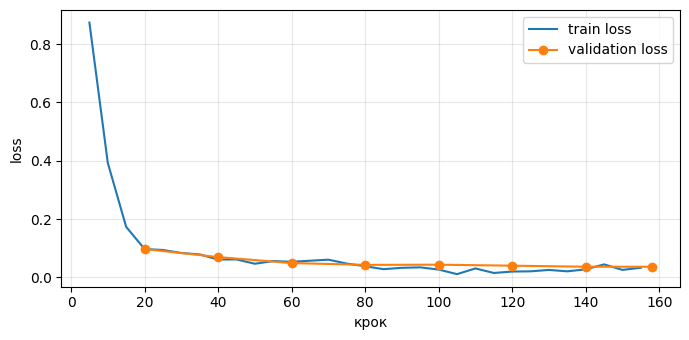

 step  eval_loss
   20     0.0974
   40     0.0697
   60     0.0493
   80     0.0431
  100     0.0437
  120     0.0403
  140     0.0367
  158     0.0366


In [ ]:
# Криві training / validation loss
import matplotlib.pyplot as plt
log = pd.DataFrame(trainer.state.log_history)
tr = log.dropna(subset=["loss"])[["step", "loss"]]
ev = log.dropna(subset=["eval_loss"])[["step", "eval_loss"]]
plt.figure(figsize=(7, 3.5))
plt.plot(tr["step"], tr["loss"], label="train loss")
plt.plot(ev["step"], ev["eval_loss"], marker="o", label="validation loss")
plt.xlabel("крок"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(ev.round(4).to_string(index=False))

## 1.5. Порівняння до і після

Порівняння робиться на тому самому тестовому наборі (300 запитань) і на тих самих прикладах. Базова модель — Qwen3-4B з найкращим промптом (few-shot, обраний за val), донавчена — Qwen3-4B + QLoRA з коротким промптом. Нижче:
1. метрики донавченої моделі поруч з усіма базовими промптами;
2. ті самі 10 тестових прикладів до і після, кількість виправлених і зіпсованих відповідей на всьому тесті;
3. підсумкова таблиця і F1 по кожній темі до і після;
4. аналіз помилок донавченої моделі: звіт по темах, найчастіші плутанини, залежність від довжини запитання, приклади помилок;
5. перевірка 5 загальних запитів поза задачею: чи не погіршились відповіді моделі.

In [ ]:
# Модель ПІСЛЯ донавчання: той самий тест, короткий системний промпт (35 токенів замість 2116 у найкращого few-shot промпту)
ft = trainer.model
ft.eval()
ft.config.use_cache = True
t0 = time.time()
outs_ft = predict(ft, SYS_SHORT, texts)
dt_ft = time.time() - t0
m_ft, pred_ft = evaluate(outs_ft, gold)
print(f"Після донавчання (короткий промпт): { {k: float(v) for k, v in m_ft.items()} }; час оцінювання {dt_ft:.0f} с")
for name in base:
    print(f"До донавчання ({name}):", {k: float(v) for k, v in base[name]["metrics"].items()}, f"; час оцінювання {base[name]['time']:.0f} с")

ft.save_pretrained("ft_adapter")
import os
adapter_mb = sum(os.path.getsize(os.path.join("ft_adapter", f)) for f in os.listdir("ft_adapter") if f.endswith(".safetensors")) / 1e6
print(f"Розмір адаптера: {adapter_mb:.1f} MB")

Після донавчання (короткий промпт): {'Валідний JSON, %': 100.0, 'Accuracy, %': 83.0, 'Macro-F1, %': 80.9}; час оцінювання 125 с
До донавчання (довгий промпт): {'Валідний JSON, %': 99.7, 'Accuracy, %': 62.7, 'Macro-F1, %': 59.0} ; час оцінювання 208 с
До донавчання (короткий промпт): {'Валідний JSON, %': 98.0, 'Accuracy, %': 0.3, 'Macro-F1, %': 0.9} ; час оцінювання 99 с
Розмір адаптера: 132.2 MB


In [ ]:
# Ті самі 10 тестових прикладів: до (найкращий промпт) і після донавчання
b = base[best]['pred']
for i in range(10):
    print(f"істина: {gold[i]} | до: {b[i]} {'✓' if b[i]==gold[i] else '✗'} | після: {pred_ft[i]} {'✓' if pred_ft[i]==gold[i] else '✗'}")
    print('   ', repr(texts[i][:100]))
fixed = sum(1 for x, y, g in zip(b, pred_ft, gold) if x != g and y == g)
broken = sum(1 for x, y, g in zip(b, pred_ft, gold) if x == g and y != g)
print()
print(f"На всьому тесті: виправлено {fixed}, зіпсовано {broken}; правильних до {sum(x==g for x,g in zip(b,gold))}, після {sum(y==g for y,g in zip(pred_ft,gold))} з {len(gold)}")


істина: працевлаштування | до: сімейне право ✗ | після: працевлаштування ✓
    "Хто вважається непрацездатними членами сім'ї?"
істина: цивільне право | до: цивільне право ✓ | після: військове право ✗
    'Скільки часу роблять ДНК-експертизу?\nСкільки часу роблять ДНК-експертизу?'
істина: оподаткування | до: оподаткування ✓ | після: оподаткування ✓
    'Періодично замовляю товари з закордону (Китай, Америка), в о...\nПеріодично замовляю товари з закордо'
істина: військове право | до: військове право ✓ | після: військове право ✓
    'Проходжу базову військову підготовку, але є рішення ВЛК про те, що я...\nПроходжу базову військову пі'
істина: військове право | до: військове право ✓ | після: військове право ✓
    'Чи є закон про  звільнення  від служби військовослужбовців які втратили...?\n... близького родича на '
істина: сімейне право | до: цивільне право ✗ | після: сімейне право ✓
    "Як мені офіційно юридично довести родинні зв'язки з двоюрідним дядьком?\nМоя бабуся ще жива, це рідна

In [ ]:
# Підсумкова таблиця до / після на тому самому тесті та F1 по темах
from sklearn.metrics import f1_score
rows = []
for name, d in base.items():
    rows.append({"модель": f"Qwen3-4B, {name}", **{k: round(float(v), 1) for k, v in d["metrics"].items()}, "час, с": round(d["time"])})
rows.append({"модель": "Qwen3-4B + QLoRA, короткий промпт", **{k: round(float(v), 1) for k, v in m_ft.items()}, "час, с": round(dt_ft)})
display(pd.DataFrame(rows))
f_b = f1_score(gold, base[best]["pred"], labels=LABELS, average=None, zero_division=0)
f_a = f1_score(gold, pred_ft, labels=LABELS, average=None, zero_division=0)
display(pd.DataFrame({"тема": LABELS, "у тесті": [sum(g == l for g in gold) for l in LABELS], "F1 до": f_b.round(3), "F1 після": f_a.round(3), "різниця": (f_a - f_b).round(3)}).sort_values("різниця"))


,модель,"Валідний JSON, %","Accuracy, %","Macro-F1, %","час, с"
0,"Qwen3-4B, довгий промпт",99.7,62.7,59.0,208
1,"Qwen3-4B, короткий промпт",98.0,0.3,0.9,99
2,"Qwen3-4B, few-shot промпт",100.0,65.7,63.0,612
3,"Qwen3-4B + QLoRA, короткий промпт",100.0,83.0,80.9,125


,тема,у тесті,F1 до,F1 після,різниця
1,сімейне право,46,0.800,0.864,0.064
9,імміграція та еміграція,16,0.667,0.750,0.083
8,права внутрішньо переміщених осіб,17,0.682,0.774,0.092
0,військове право,78,0.766,0.909,0.143
6,оподаткування,21,0.826,0.976,0.150
5,автовласникам,23,0.773,0.936,0.163
3,працевлаштування,28,0.615,0.831,0.215
4,пенсії та соціальні виплати,23,0.474,0.718,0.244
2,соціальний захист,29,0.358,0.610,0.252
7,цивільне право,19,0.341,0.722,0.381


In [ ]:
# Чому помилки: довжина запитання і ще 16 прикладів помилок
tl = np.array([len(t) for t in texts])
wrong = np.array([g != p for g, p in zip(gold, pred_ft)])
bins = [0, 80, 150, 300, 10**6]
for lo, hi in zip(bins[:-1], bins[1:]):
    mk = (tl >= lo) & (tl < hi)
    if mk.sum():
        print(f"довжина {lo}-{hi if hi < 10**6 else 'більше'} символів: {mk.sum()} запитань, помилок {wrong[mk].sum()} ({100 * wrong[mk].mean():.0f} %)")
print()
for g, p, t in [(g, p, t) for g, p, t in zip(gold, pred_ft, texts) if g != p][14:30]:
    print(f"істина: {g} | модель: {p} | {t[:130]!r}")


довжина 0-80 символів: 142 запитань, помилок 29 (20 %)
довжина 80-150 символів: 74 запитань, помилок 8 (11 %)
довжина 150-300 символів: 58 запитань, помилок 7 (12 %)
довжина 300-більше символів: 26 запитань, помилок 7 (27 %)

істина: пенсії та соціальні виплати | модель: працевлаштування | 'Що робити у випадку, якщо роботодавець не хоче подавати заяву-розрахунок…?\n…до пенсійного фонду, щоб перерахувати декретні виплати'
істина: цивільне право | модель: соціальний захист | 'Я проживаю в місті на 1 поверху.в нашому домі криси ходять як у себе дома..\n...таракани, миші і блохи. заявку в жек подали але так'
істина: сімейне право | модель: імміграція та еміграція | 'Дозвіл на виїзд дитини за кордон\nЧи потрібно дозвіл від батька при виїзді дитини з мамою на автобусну екскурсію в Румунію? Батьки '
істина: соціальний захист | модель: сімейне право | 'Я є військовослужбовцем. Чи можу я не сплачувати аліменти, поки служу?'
істина: сімейне право | модель: імміграція та еміграція | 'Як отримати 

In [ ]:
# Аналіз помилок донавченої моделі
from sklearn.metrics import classification_report
print(classification_report(gold, pred_ft, labels=LABELS, zero_division=0, digits=3))

err = [(g, p, o, t) for g, p, o, t in zip(gold, pred_ft, outs_ft, texts) if g != p]
print(f"Помилок: {len(err)} з {len(gold)}")
print("Найчастіші пари (істина -> передбачення):")
print(pd.Series([f"{g} -> {p}" for g, p, _, _ in err]).value_counts().head(8).to_string())
print()
for g, p, o, t in err[:14]:
    print(f"істина: {g} | модель: {p} | {t[:110]!r}")

                                   precision    recall  f1-score   support

                  військове право      0.921     0.897     0.909        78
                    сімейне право      0.905     0.826     0.864        46
                соціальний захист      0.600     0.621     0.610        29
                 працевлаштування      0.730     0.964     0.831        28
      пенсії та соціальні виплати      0.875     0.609     0.718        23
                    автовласникам      0.917     0.957     0.936        23
                    оподаткування      1.000     0.952     0.976        21
                   цивільне право      0.765     0.684     0.722        19
права внутрішньо переміщених осіб      0.857     0.706     0.774        17
          імміграція та еміграція      0.625     0.938     0.750        16

                         accuracy                          0.830       300
                        macro avg      0.819     0.815     0.809       300
                     we

In [ ]:
# Загальні запити поза задачею: чи не погіршилася модель? Порівнюємо базову модель (адаптер вимкнено) і донавчену
general = [
    "Поясни простими словами, що таке інфляція.",
    "Напиши коротку функцію на Python, яка перевіряє, чи є число простим.",
    "Яка столиця Франції і чим вона відома?",
    "Переклади англійською: «Добрий день, як справи?»",
    "Склади план підготовки до іспиту на 3 дні.",
]
def chat(mdl, q, n=120):
    prompt = tok.apply_chat_template([{"role": "user", "content": q}], tokenize=False, add_generation_prompt=True, enable_thinking=False)
    enc = tok(prompt, return_tensors="pt").to(mdl.device)
    with torch.no_grad():
        out = mdl.generate(**enc, max_new_tokens=n, do_sample=False, pad_token_id=tok.pad_token_id)
    return tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).replace("\n", " ")

for q in general:
    with ft.disable_adapter():
        before = chat(ft, q)
    after = chat(ft, q)
    print("Запит:", q)
    print("  до:    ", before[:260])
    print("  після: ", after[:260])
    print()

Запит: Поясни простими словами, що таке інфляція.
  до:     Ось просте пояснення інфляції:  **Інфляція** — це ситуація, коли **ціни на товари і послуги зростають**, а **дохід людей не зростає на стільки ж**. В результаті, одне гроше стає менш цінним.  Наприклад:   - Пів року тому 1 кілограм цибулки кошту
  після:  Інфляція — це ситуація, коли ціни на товари та послуги підвищуються, а це означає, що одне грошей стає менш цінним. Наприклад, якщо півтора роки тому одне яблуко коштувало 10 гривень, а тепер воно коштує 20 гривень, то це приклад і

Запит: Напиши коротку функцію на Python, яка перевіряє, чи є число простим.
  до:     Ось коротка функція на Python, яка перевіряє, чи є число простим:  ```python def is_prime(n):     if n <= 1:         return False     if n == 2:         return True     if n % 2 == 0:         return False     for i in range(3, int(n**0.5) + 1, 2):         if n
  після:  Вот проста функція на Python, яка перевіряє, чи є число простим:  ```python def is_prime(n):  

# Мій звіт

## 1. Задача і чому потрібне донавчання
Задача: класифікація юридичних звернень громадян українською мовою за темою. Вхід — текст запитання (заголовок і опис, до 700 символів), вихід — JSON {"category": "..."} з однією з 10 тем: військове право, сімейне право, соціальний захист, працевлаштування, пенсії та соціальні виплати, автовласникам, оподаткування, цивільне право, права внутрішньо переміщених осіб, імміграція та еміграція. Такою моделлю можуть користуватися юридичні консультації, гарячі лінії та чат-боти державних сервісів, щоб автоматично спрямовувати звернення до потрібного фахівця.

Чому не лише промпт: без донавчання модель з коротким промптом (35 токенів) вигадує власні назви тем і дає accuracy 0,3 %. Довгий промпт (612 токенів, список тем з описами) дає 62,7 %, а найкращий з перевірених, few-shot (2116 токенів, по 2 приклади на тему), — 65,7 %, при цьому кожен запит у 60 разів довший за короткий. Межі між темами задаються розміткою датасету, а не фактами з документів, тому RAG тут не допомагає: зовнішні знання не потрібні, потрібні стабільний формат і навчена межа між класами.

## 2. Модель і дані
Модель: Qwen3-4B (чат-версія, thinking вимкнено через шаблон). Обрано версію з інструкціями, бо задача — виконання інструкції у фіксованому форматі, і вона вже вміє тримати JSON (98–99,7 % валідних відповідей без донавчання). Розмір 4B: у 4-бітному форматі NF4 ваги займають 2,68 GB, тож QLoRA вміщується в безкоштовну T4 (15 GB), а модель достатньо добре розуміє українську. Менші моделі, ймовірно, слабші в українській, а 7–8B тренувалися б на T4 надто довго.

Дані: ua-l/topics на Hugging Face (організація UA-LAWYER; походження вихідних запитань на сторінці не описано), ліцензія CC BY-NC 4.0 (некомерційне використання, для навчальної роботи підходить). У датасеті 3246 записів і 39 тем. Відібрано 10 предметних тем з найбільших, без нетематичних «inshe» (інше, 527 записів) і «sudova_praktika» (судова практика, 138): 1720 записів, 1718 після видалення дублікатів. Формат: text = заголовок + опис, completion = {"category": "..."}. Приклади: «Як довго можна отримувати допомогу по безробіттю?» → пенсії та соціальні виплати; «Чи є відпустка після поранення?» → військове право.
Розбиття: стратифіковане train / val / test = 1268 / 150 / 300 (random_state = 42). Дублікати видалено до розбиття, перетин множин перевіряється assert-ом. Val використовується лише для контролю тренування, test — лише для оцінки. Промпт до донавчання обрано за val (few-shot 66,7 % проти 62,7 % у довгого), а не за тестом.

## 3. Метрика й результат до донавчання
Метрики: accuracy, macro-F1 і частка валідного JSON. Класи незбалансовані (у тесті 78 запитань з військового права і лише 16 з імміграції), тому до accuracy додано macro-F1, який рахує кожну тему однаково. Валідний JSON показує, чи тримає модель формат. Орієнтир «завжди найчастіший клас» дає accuracy 26,0 %.

| Модель (тест, 300 зразків) | Промпт | Валідний JSON | Accuracy | Macro-F1 | Час оцінювання |
|---|---|---|---|---|---|
| Найчастіший клас | — | — | 26,0 % | — | — |
| Qwen3-4B без донавчання | довгий, 612 токенів | 99,7 % | 62,7 % | 59,0 % | 208 с |
| Qwen3-4B без донавчання | короткий, 35 токенів | 98,0 % | 0,3 % | 0,9 % | 99 с |
| Qwen3-4B без донавчання | few-shot, 2116 токенів | 100 % | 65,7 % | 63,0 % | 612 с |

Найкращий промпт до донавчання — few-shot (обрано за val: accuracy 66,7 % проти 62,7 % у довгого). 10 прикладів виходів моделі наведено у виводі клітинки з базовою оцінкою.

## 4. Метод донавчання і гіперпараметри
QLoRA: базова модель у NF4 з double quantization, обчислення у fp16 (T4 не підтримує bf16, тому LoRA-параметри переведено у float32 для GradScaler). LoRA: r = 16, alpha = 32, dropout = 0,05, target_modules = all-linear; тренується 33,0 млн параметрів, тобто 0,81 % від 4,06 млрд. SFT через TRL у форматі prompt / completion, loss рахується лише на відповіді, системний промпт короткий (35 токенів).
Гіперпараметри: learning rate 2e-4 (cosine, warmup 8 кроків; типове значення для LoRA), batch 4 × accumulation 4 = 16 (малий мікробатч економить памʼять, накопичення дає стабільніші градієнти), 2 епохи = 158 кроків (після ~100 кроків val loss виходить на плато), max_length 384, gradient checkpointing. r = 16 і alpha = 32 (масштаб 2) взято зі стандартних рекомендацій QLoRA, окремий підбір не проводився. 15 з 1268 тренувальних прикладів (1,2 %) довші за 384 токени й обрізаються, ефект малий. Тривалість тренування 26,0 хв, пікова памʼять GPU 3,99 GB, розмір адаптера 132 MB.

| Крок | Train loss | Val loss |
|---|---|---|
| 20 | 0,097 | 0,097 |
| 40 | 0,061 | 0,070 |
| 60 | 0,054 | 0,049 |
| 80 | 0,038 | 0,043 |
| 100 | 0,027 | 0,044 |
| 120 | 0,020 | 0,040 |
| 140 | 0,028 | 0,037 |
| 158 | 0,033 | 0,037 |

Перенавчання не помічено: val loss знижується з 0,097 до 0,037 і не зростає, різниця між train і val мала. Тому гіперпараметри після першого запуску не змінювалися (єдина зміна — приведення LoRA-параметрів до float32, бо без цього тренування падало на T4 з помилкою BFloat16).

## 5. Результат після донавчання
| Модель (той самий тест) | Промпт | Валідний JSON | Accuracy | Macro-F1 | Час оцінювання |
|---|---|---|---|---|---|
| Qwen3-4B без донавчання (few-shot, найкращий за val) | 2116 токенів | 100 % | 65,7 % | 63,0 % | 612 с |
| Qwen3-4B + QLoRA | 35 токенів | 100 % | 83,0 % | 80,9 % | 125 с |

Після донавчання accuracy зросла на 17,3 в. п., macro-F1 — на 17,9 в. п., формат лишився стабільним (100 % валідного JSON), а промпт скоротився з 2116 до 35 токенів, тому оцінювання пройшло у 4,9 раза швидше (125 с проти 612 с).

На тих самих 300 зразках донавчання виправило 61 помилку базової моделі і зіпсувало 9 правильних відповідей (правильних було 197, стало 249). Порівняння на перших 10 зразках до і після наведено в окремій клітинці розділу 1.5.

## 6. Аналіз помилок
Помилок 51 з 300 (17 %). F1 покращився в усіх 10 темах, найбільше — у цивільному праві (+0,38). Найкращі теми після донавчання: оподаткування (F1 0,976), автовласникам (0,936), військове право (0,909). Найслабші: соціальний захист (0,610), пенсії та соціальні виплати (0,718) і цивільне право (0,722).

Чому модель помиляється:
1. Суміжні теми. Найчастіші плутанини: права ВПО → соціальний захист (5), пенсії → працевлаштування (5), сімейне право → імміграція та еміграція (5), пенсії → соціальний захист (4). Питання про стаж у трудовій книжці стосується і пенсій, і праці, а виплати ВПО — і прав ВПО, і соціального захисту. Тут модель обирає правдоподібну тему, яка відрізняється від розмітки.
2. Неоднозначна або шумна розмітка. Приклад: «Скільки часу роблять ДНК-експертизу?» модель віднесла до військового права, у розмітці — цивільне право. Джерело розмітки на сторінці датасету не описане, а частина запитань підходить до кількох тем, тому деякі мітки спірні.
3. Довжина запитання. Частка помилок: 0–80 символів — 20 %, 80–150 — 11 %, 150–300 — 12 %, понад 300 — 27 %. Короткі запитання без контексту дають мало ознак, а довгі часто описують кілька проблем одразу. Для 15 прикладів з довжиною понад 384 токени (більше за max_length) кінець запитання під час навчання відрізався.
4. Малі класи. У тесті на тему припадає 16–29 зразків, тому одна помилка змінює F1 на 3–6 в. п. і різниці між слабкими темами не варто вважати суворо значущими.

Загальні запити поза задачею (інфляція, функція на Python, столиця Франції, переклад, план підготовки): модель і далі відповідає звичайним текстом, а не JSON, переклад ідентичний, код схожий. Деградація легка: зʼявився русизм («Вот проста функція») і одна вигадана памʼятка Парижа («Пірати»), відповіді стали коротшими і з меншою кількістю форматування. Помилку «одне гроше» робила й базова модель, тому до донавчання її не віднесено. Перевірку зроблено лише на 5 запитах і 120 токенах, тому це якісна оцінка.

## 7. Висновок
QLoRA на 1268 прикладах за 26 хв на безкоштовній T4 підняла accuracy з 65,7 % до 83,0 % і macro-F1 з 63,0 % до 80,9 % порівняно з найкращим промптом, дала 100 % валідного JSON і зменшила промпт з 2116 до 35 токенів. Перенавчання немає, адаптер займає 132 MB і не потребує зберігання ваг у репозиторії. Обмеження: тест містить лише 300 зразків, один запуск з одним seed, суміжні теми плутаються, на загальних запитах є легкі огріхи (русизм, коротші відповіді). Що можна покращити: об'єднати суміжні теми або додати більше даних для малих класів, перевірити 3 епохи і r = 32, додати міцнішу перевірку на загальних запитах.
